In [1]:

import pandas as pd
from io import StringIO

csv_data = """case_id,activity,timestamp
O1001,Order Created,2026-10-01 09:00:00
O1001,Payment Confirmed,2026-10-01 09:30:00
O1001,Order Packed,2026-10-01 11:00:00
O1001,Order Shipped,2026-10-01 13:00:00
O1002,Order Created,2026-10-01 10:00:00
O1002,Payment Confirmed,2026-10-01 10:20:00
O1002,Order Packed,2026-10-01 15:00:00
O1002,Order Shipped,2026-10-02 09:00:00
O1003,Order Created,2026-10-02 08:00:00
O1003,Payment Confirmed,2026-10-02 08:45:00
O1003,Order Packed,2026-10-02 10:00:00
O1003,Order Shipped,2026-10-02 12:00:00
O1004,Order Created,2026-10-02 09:00:00
O1004,Payment Confirmed,2026-10-02 09:15:00
O1004,Order Packed,2026-10-02 18:00:00
O1004,Order Shipped,2026-10-03 11:00:00
O1005,Order Created,2026-10-03 08:30:00
O1005,Payment Confirmed,2026-10-03 09:00:00
O1005,Order Packed,2026-10-03 10:30:00
O1005,Order Packed,2026-10-03 11:00:00
O1005,Order Shipped,2026-10-03 14:00:00
O1006,Order Created,2026-10-03 10:00:00
O1006,Payment Confirmed,2026-10-03 10:10:00
O1006,Order Packed,2026-10-03 12:00:00
O1006,Order Shipped,2026-10-04 10:00:00
"""

df = pd.read_csv(StringIO(csv_data))
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Rows:", len(df))
print("Unique cases:", df["case_id"].nunique())
display(df.head(10))


Rows: 25
Unique cases: 6


,case_id,activity,timestamp
0,O1001,Order Created,2026-10-01 09:00:00
1,O1001,Payment Confirmed,2026-10-01 09:30:00
2,O1001,Order Packed,2026-10-01 11:00:00
3,O1001,Order Shipped,2026-10-01 13:00:00
4,O1002,Order Created,2026-10-01 10:00:00
5,O1002,Payment Confirmed,2026-10-01 10:20:00
6,O1002,Order Packed,2026-10-01 15:00:00
7,O1002,Order Shipped,2026-10-02 09:00:00
8,O1003,Order Created,2026-10-02 08:00:00
9,O1003,Payment Confirmed,2026-10-02 08:45:00


In [2]:

print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique activities:", df["activity"].nunique())

# Sort events chronologically within each order
df = df.sort_values(
    ["case_id", "timestamp"]
).reset_index(drop=True)

print("\nEvents per order:")
print(df.groupby("case_id").size())


Missing values:
case_id      0
activity     0
timestamp    0
dtype: int64

Duplicate rows: 0
Unique activities: 4

Events per order:
case_id
O1001    4
O1002    4
O1003    4
O1004    4
O1005    5
O1006    4
dtype: int64


In [3]:

case_summary = (
    df.groupby("case_id")["timestamp"]
    .agg(start_time="min", end_time="max")
    .reset_index()
)

case_summary["cycle_time_hours"] = (
    case_summary["end_time"] - case_summary["start_time"]
).dt.total_seconds() / 3600

print("Cycle time for each order:")
display(
    case_summary.sort_values(
        "cycle_time_hours", ascending=False
    ).round({"cycle_time_hours": 2})
)

print(
    "Average cycle time:",
    round(case_summary["cycle_time_hours"].mean(), 2),
    "hours"
)


Cycle time for each order:


,case_id,start_time,end_time,cycle_time_hours
3,O1004,2026-10-02 09:00:00,2026-10-03 11:00:00,26.0
5,O1006,2026-10-03 10:00:00,2026-10-04 10:00:00,24.0
1,O1002,2026-10-01 10:00:00,2026-10-02 09:00:00,23.0
4,O1005,2026-10-03 08:30:00,2026-10-03 14:00:00,5.5
0,O1001,2026-10-01 09:00:00,2026-10-01 13:00:00,4.0
2,O1003,2026-10-02 08:00:00,2026-10-02 12:00:00,4.0


Average cycle time: 14.42 hours


In [4]:

df["next_activity"] = df.groupby("case_id")["activity"].shift(-1)
df["next_timestamp"] = df.groupby("case_id")["timestamp"].shift(-1)

df["step_hours"] = (
    df["next_timestamp"] - df["timestamp"]
).dt.total_seconds() / 3600

step_summary = (
    df.dropna(subset=["next_activity"])
    .groupby(["activity", "next_activity"])["step_hours"]
    .agg(["mean", "max", "count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

step_summary = step_summary.rename(columns={
    "activity": "from_activity",
    "next_activity": "to_activity",
    "mean": "avg_hours",
    "max": "max_hours",
    "count": "cases"
})

display(step_summary.round(2))


,from_activity,to_activity,avg_hours,max_hours,cases
2,Order Packed,Order Shipped,10.67,22.00,6
3,Payment Confirmed,Order Packed,3.25,8.75,6
1,Order Packed,Order Packed,0.50,0.50,1
0,Order Created,Payment Confirmed,0.42,0.75,6


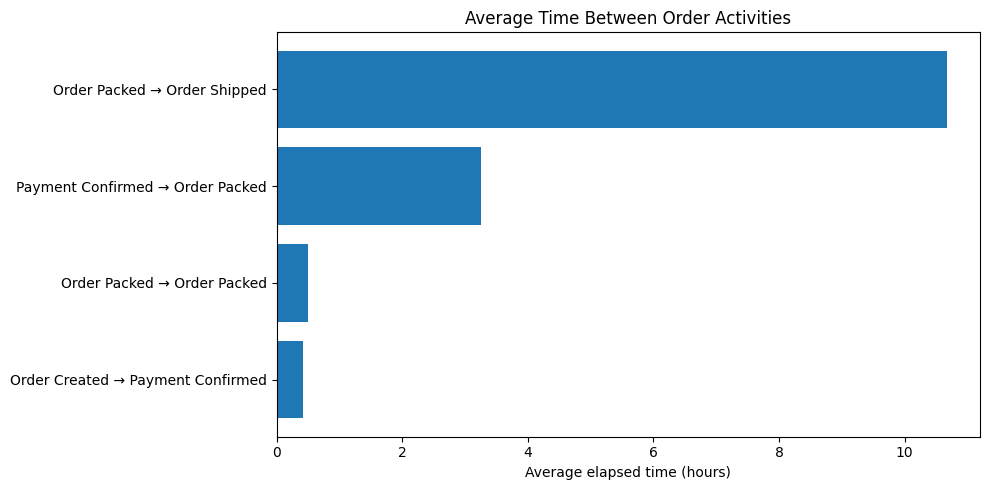

In [5]:

import matplotlib.pyplot as plt

plot_data = step_summary.sort_values("avg_hours")

labels = (
    plot_data["from_activity"] + " → " + plot_data["to_activity"]
)

plt.figure(figsize=(10, 5))
plt.barh(labels, plot_data["avg_hours"])
plt.xlabel("Average elapsed time (hours)")
plt.title("Average Time Between Order Activities")
plt.tight_layout()
plt.show()


In [6]:

# Save project outputs
df.to_csv("event_log.csv", index=False)
case_summary.to_csv("case_cycle_times.csv", index=False)
step_summary.to_csv("process_step_analysis.csv", index=False)

print("Saved:")
print("- event_log.csv")
print("- case_cycle_times.csv")
print("- process_step_analysis.csv")


Saved:
- event_log.csv
- case_cycle_times.csv
- process_step_analysis.csv


In [7]:
from google.colab import files

files.download("event_log.csv")
files.download("case_cycle_times.csv")
files.download("process_step_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import sqlite3
import pandas as pd

conn = sqlite3.connect("process_mining.db")

df.to_sql("event_log", conn, if_exists="replace", index=False)

query = """
WITH ordered_events AS (
    SELECT
        case_id,
        activity,
        timestamp,
        LEAD(activity) OVER (
            PARTITION BY case_id ORDER BY timestamp
        ) AS next_activity,
        LEAD(timestamp) OVER (
            PARTITION BY case_id ORDER BY timestamp
        ) AS next_timestamp
    FROM event_log
)
SELECT
    activity AS from_activity,
    next_activity AS to_activity,
    ROUND(
        AVG(
            (julianday(next_timestamp) - julianday(timestamp)) * 24
        ), 2
    ) AS avg_hours,
    COUNT(*) AS transitions
FROM ordered_events
WHERE next_activity IS NOT NULL
GROUP BY activity, next_activity
ORDER BY avg_hours DESC;
"""

sql_results = pd.read_sql_query(query, conn)
display(sql_results)

conn.close()


,from_activity,to_activity,avg_hours,transitions
0,Order Packed,Order Shipped,10.67,6
1,Payment Confirmed,Order Packed,3.25,6
2,Order Packed,Order Packed,0.50,1
3,Order Created,Payment Confirmed,0.42,6


In [9]:

sql_query = """
WITH ordered_events AS (
    SELECT
        case_id,
        activity,
        timestamp,
        LEAD(activity) OVER (
            PARTITION BY case_id ORDER BY timestamp
        ) AS next_activity,
        LEAD(timestamp) OVER (
            PARTITION BY case_id ORDER BY timestamp
        ) AS next_timestamp
    FROM event_log
)
SELECT
    activity AS from_activity,
    next_activity AS to_activity,
    ROUND(
        AVG(
            (julianday(next_timestamp) - julianday(timestamp)) * 24
        ), 2
    ) AS avg_hours,
    COUNT(*) AS transitions
FROM ordered_events
WHERE next_activity IS NOT NULL
GROUP BY activity, next_activity
ORDER BY avg_hours DESC;
"""

with open("process_analysis.sql", "w") as f:
    f.write(sql_query.strip() + "\n")

print("SQL file created successfully.")


SQL file created successfully.


In [10]:

from google.colab import files
files.download("process_analysis.sql")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>